# Slides: transmission model and epidemiological projections

Builds a Beamer deck, as a `.tex` file and its figures, from a stored run: model structure
and assumptions, calibration and fits, scenarios, and projected epidemiological impact.
Every number on the slides is read from the run and from `vacf.economics.study`, so
rebuilding against the MASSIVE run updates the deck.

The deck reuses the theme (`Unipd`) and diagrams of the Kiribati talk
(`images/TB Model.pdf`, `images/ICE_TB.png`, `images/Classif.pdf`), so it compiles in that
folder. Copy `vietnam_model_slides.tex` and the `images_2/` folder from `OUT` into the
Kiribati slides folder, and build there as usual. Check that the reused model diagram still
matches this model, which has no preventive treatment and no hard-to-reach stratum.

In [1]:
from vacf.constants import OUTPUT_PATH
from vacf.economics import analysis, slides, study

RUN = OUTPUT_PATH / "local-sample-n100"
OUT = RUN / "slides"

DETAILS = dict(
    title="Active TB case finding in Viet Nam: transmission model and epidemiological projections",
    short_title="Viet Nam ACF TB modelling",
    author="Romain Ragonnet, PhD, MSc",
    short_author="Romain Ragonnet",
    institute=(
        r"Epidemiological Modelling Unit (EMU)\\"
        r"School of Public Health and Preventive Medicine\\"
        r"Monash University, Melbourne, Australia"
    ),
    date=r"\today",
)

/Users/rrag0004/Documents/agentic_code/vietnam_acf_cea/.pixi/envs/default/lib/python3.13/site-packages/arviz/__init__.py:110: MigrationWarning: arviz.InferenceData is no longer available on the arviz package; ArviZ now uses xarray's DataTree for the same role. See the migration guide: https://python.arviz.org/en/latest/user_guide/migration_guide.html#datatree
  warnings.warn(


/Users/rrag0004/Documents/agentic_code/vietnam_acf_cea/.pixi/envs/default/lib/python3.13/site-packages/arviz/__init__.py:110: MigrationWarning: arviz.InferenceData is no longer available on the arviz package; ArviZ now uses xarray's DataTree for the same role. See the migration guide: https://python.arviz.org/en/latest/user_guide/migration_guide.html#datatree
  warnings.warn(


In [2]:
posterior = analysis.load_posterior_outputs(RUN)
tex = slides.write_slides(posterior, OUT, run_name=RUN.name, **DETAILS)
print(f"wrote {tex}")
for path in sorted((OUT / slides.FIGURE_DIR).glob("*.pdf")):
    print(f"      {path}")

wrote /Users/rrag0004/Documents/agentic_code/vietnam_acf_cea/outputs/local-sample-n100/slides/vietnam_model_slides.tex
      /Users/rrag0004/Documents/agentic_code/vietnam_acf_cea/outputs/local-sample-n100/slides/images_2/cumulative.pdf
      /Users/rrag0004/Documents/agentic_code/vietnam_acf_cea/outputs/local-sample-n100/slides/images_2/fits.pdf
      /Users/rrag0004/Documents/agentic_code/vietnam_acf_cea/outputs/local-sample-n100/slides/images_2/impact_acf_cxr_xpert.pdf
      /Users/rrag0004/Documents/agentic_code/vietnam_acf_cea/outputs/local-sample-n100/slides/images_2/impact_acf_xpert.pdf


## Preview of the figures

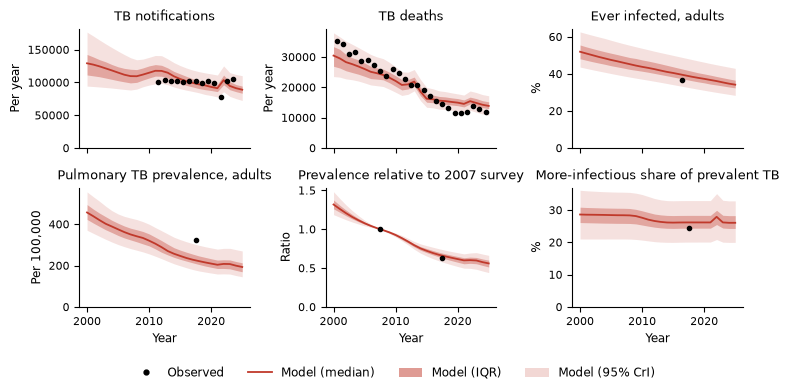

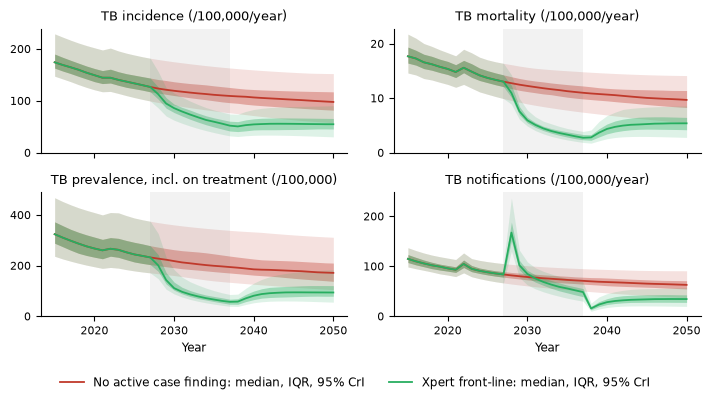

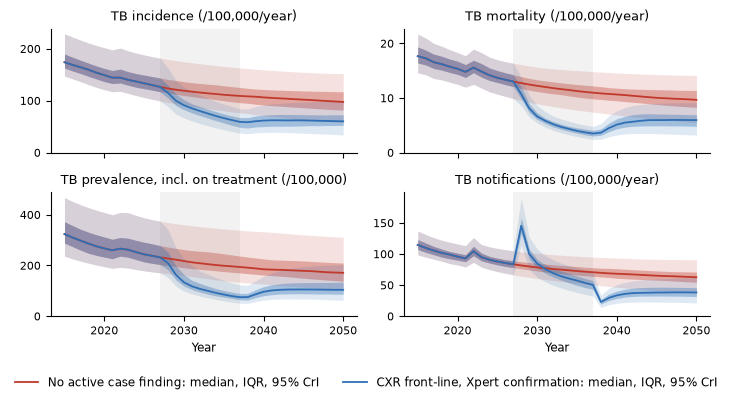

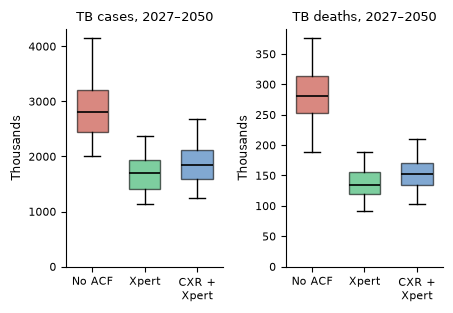

In [3]:
display(slides.fit_figure(posterior))
for arm in study.SCENARIOS[1:]:
    display(slides.impact_figure(posterior, arm.name))
display(slides.cumulative_figure(posterior))